# Exercise 2 — Transit photometry of a bright star

*Covers notebooks 02, 05. Difficulty: ★★☆☆☆*

Transit follow-up needs millimagnitude precision on stars that are bright by survey standards. On the WCC the limit is photon noise on one side and the shallow CMOS well on the other.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

### 2.1 — A bright host

A K2V host at r = 16 (AB) observed at 60 s cadence in zwo:r. What is the smallest read split that
keeps each frame unsaturated, and the resulting precision per 60 s point in ppm?

In [2]:
READS = (1, 2, 3, 6, 10, 30, 60, 120, 240)

def choose_reads(sim, t, reads=READS, **kw):
    """Smallest read count whose per-frame image has no saturated pixel; (None, last result) if none works."""
    for n in reads:
        r = sim.get_image_snr(t, n_reads=n, warn=False, **kw)
        if not np.any(r["saturated"]):
            return n, r
    return None, r

sim = Simulation.from_sensorfilter("zwo:r", get_scene("K2V", mag=16, bandpass="sdss_r", magsys="abmag"))
n, r = choose_reads(sim, 60)
print(f"r = 16: {n} x {60 / n:.0f} s per point, {1e6 / r['snr']:.0f} ppm per point")

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


r = 16: 6 x 10 s per point, 1123 ppm per point


### 2.2 — A simulated transit

Simulate a 1 % deep transit (P = 1 d, a/R* = 10, i = 88°) of a K2V host at r = 19 over ±0.12 d
at 60 s cadence, and plot it. Compare the out-of-transit scatter with the ETC's `flux_err`.

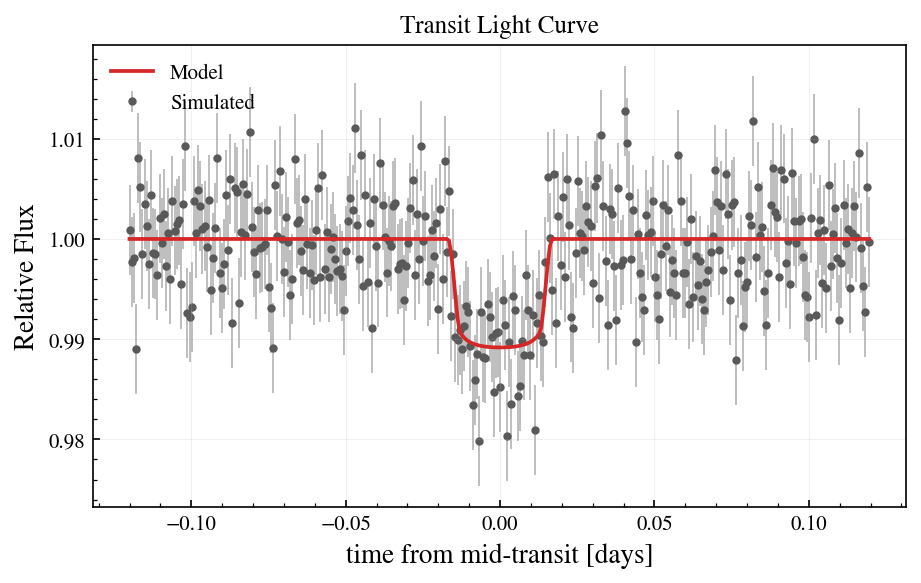

out-of-transit scatter 4645 ppm, flux_err 4489 ppm


In [3]:
from wcc_etc import TransitModel, LightCurveSimulator
sim.update(source__mag=19.0)
planet = TransitModel(t0=0.0, per=1.0, rp=0.1, a=10.0, inc=88.0)
time = np.arange(-0.12, 0.12, 60 / 86400)
lc = LightCurveSimulator(sim, planet).simulate(time, 60, seed=2)
fig, ax = lc.plot(); ax.set(xlabel="time from mid-transit [days]"); plt.show()
oot = np.abs(lc.time) > 0.03
print(f"out-of-transit scatter {np.std(lc.flux[oot] - lc.flux_clean[oot]) * 1e6:.0f} ppm, flux_err {lc.flux_err * 1e6:.0f} ppm")

### 2.3 — Precision versus magnitude

For K2V hosts from r = 11 to 21, tabulate the smallest read split, the precision per 60 s point
and the precision binned to one hour (white noise). Plot both against magnitude with horizontal
lines for the transit depths of Jupiter, Neptune and Earth around a Sun-like star, and of an Earth
around a 0.3 $R_\odot$ M dwarf (use `astropy.constants`).

r = 11.0: None reads,    nan ppm per point,   nan ppm per hour
r = 12.0:  240 reads,    178 ppm per point,    23 ppm per hour
r = 13.0:  120 reads,    282 ppm per point,    36 ppm per hour
r = 14.0:   60 reads,    448 ppm per point,    58 ppm per hour
r = 15.0:   30 reads,    710 ppm per point,    92 ppm per hour
r = 16.0:    6 reads,   1123 ppm per point,   145 ppm per hour
r = 17.0:    3 reads,   1781 ppm per point,   230 ppm per hour
r = 18.0:    1 reads,   2822 ppm per point,   364 ppm per hour


r = 19.0:    1 reads,   4489 ppm per point,   579 ppm per hour
r = 20.0:    1 reads,   7176 ppm per point,   926 ppm per hour


r = 21.0:    1 reads,  11615 ppm per point,  1499 ppm per hour


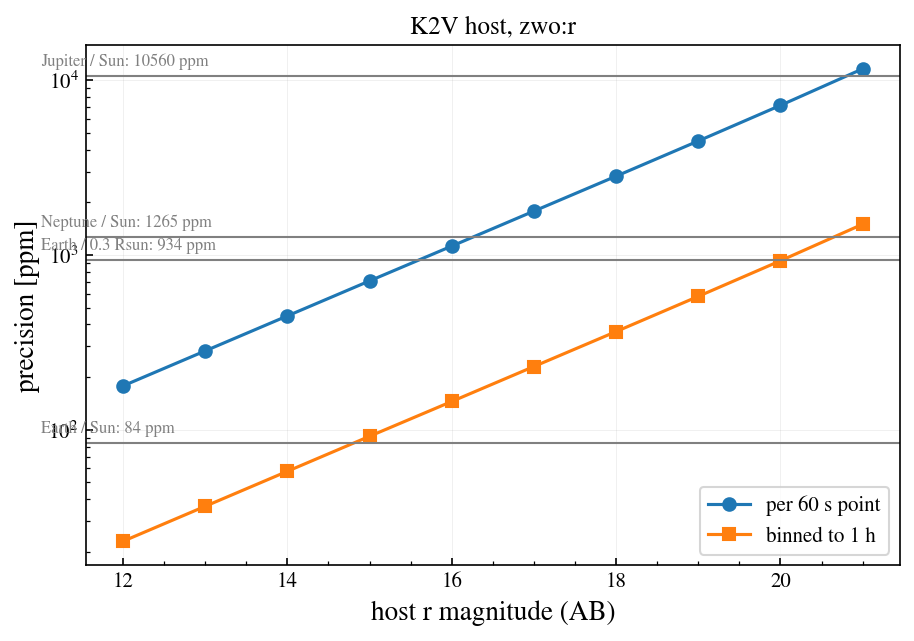

In [4]:
from astropy.constants import R_jup, R_earth, R_sun
depths = {"Jupiter / Sun": float((R_jup / R_sun) ** 2), "Neptune / Sun": float((3.88 * R_earth / R_sun) ** 2),
          "Earth / 0.3 Rsun": float((R_earth / (0.3 * R_sun)) ** 2), "Earth / Sun": float((R_earth / R_sun) ** 2)}
mags = np.arange(11, 21.1, 1.0)
rows = []
for m in mags:
    sim.update(source__mag=float(m))
    n, r = choose_reads(sim, 60)
    ppm = 1e6 / r["snr"] if n else np.nan
    rows.append((n if n else np.nan, ppm, ppm / np.sqrt(60)))
    print(f"r = {m:4.1f}: {str(n):>4} reads, {ppm:6.0f} ppm per point, {rows[-1][2]:5.0f} ppm per hour")
n_needed, ppm_point, ppm_hour = map(np.array, zip(*rows))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(mags, ppm_point, "o-", label="per 60 s point")
ax.semilogy(mags, ppm_hour, "s-", label="binned to 1 h")
for name, d in depths.items():
    ax.axhline(d * 1e6, color="0.5", lw=1); ax.text(mags[0], d * 1.15e6, f"{name}: {d * 1e6:.0f} ppm", color="0.5", fontsize=8)
ax.set(xlabel="host r magnitude (AB)", ylabel="precision [ppm]", title="K2V host, zwo:r"); ax.legend(loc="lower right")
plt.show()

### 2.4 — Detection significance

For one transit of duration $T_{14}$ = 0.8 h in a 5.8 h window at 60 s cadence, the depth
uncertainty with white noise is
$\sigma_\delta = \sigma_\mathrm{point}\sqrt{1/N_\mathrm{in} + 1/N_\mathrm{out}}$.
At which host magnitude does a Neptune/Sun transit reach 5 sigma in a single event? And an
Earth/Sun transit?

In [5]:
n_in = 0.8 * 3600 / 60; n_out = (5.8 - 0.8) * 3600 / 60
sigma_depth = ppm_point * np.sqrt(1 / n_in + 1 / n_out)
for name in ("Neptune / Sun", "Earth / Sun"):
    sig = depths[name] * 1e6 / sigma_depth
    ok = sig >= 5
    print(f"{name}: " + (f"5 sigma out to r = {mags[ok].max():.0f}" if ok.any() else "never 5 sigma in one transit") + "  (" + ", ".join(f"{m:.0f}: {s:.1f}" for m, s in zip(mags, sig)) + ")")

Neptune / Sun: 5 sigma out to r = 16  (11: nan, 12: 45.7, 13: 28.8, 14: 18.2, 15: 11.5, 16: 7.2, 17: 4.6, 18: 2.9, 19: 1.8, 20: 1.1, 21: 0.7)
Earth / Sun: never 5 sigma in one transit  (11: nan, 12: 3.0, 13: 1.9, 14: 1.2, 15: 0.8, 16: 0.5, 17: 0.3, 18: 0.2, 19: 0.1, 20: 0.1, 21: 0.0)


> 🤖 **Ask Jupyter AI:** *Turn the sigma_depth formula into a function of (ppm_point, T14_hours, window_hours, cadence_s) and plot the Neptune/Sun significance against T14 from 0.5 to 5 h for an r = 15 host.*
>
> Then ask it what systematic noise floor (in ppm per hour) would make the Earth/Sun case hopeless at every magnitude.

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/wcc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*